<h1 align="center">Rwanda Maize–Urea Trial</h1>
<h2 align="center">4. Treatment Effect Analysis</h2>

**Goal (Objective 1):** estimate how much each Urea strategy changes yield, test whether the differences are statistically significant, and check whether the answer changes by mega-environment or season.

**Why a mixed-effects model?** The four plots in a field share soil, rainfall and management. Treating 1,598 plots as independent would overstate precision. A random intercept for each field-season unit means treatment effects are estimated mostly *within* fields:

`yield ~ treatment + season + mega-environment + (1 | field-season)`

The model code is in [`src/maize/analysis.py`](../src/maize/analysis.py) and uses `statsmodels.MixedLM`.

> **Data note.** The trial data is confidential and is not in this repository. The outputs shown were produced on the real data. If you run this notebook without it, it uses the synthetic sample in `01_Data/sample/` and the numbers will differ.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "02_Notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from maize import config, data, analysis, plotting

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
MODE = config.data_mode()
OUT = config.output_paths(MODE)
print("Data source:", "confidential trial data (01_Data/raw)" if MODE == "raw" else "synthetic sample (01_Data/sample)")

Data source: confidential trial data (01_Data/raw)


In [2]:
_, combined = data.build_combined(MODE)
df = data.analysis_frame(combined)
te = analysis.treatment_effects(df)
print(f"Model: {te['n_obs']} plots in {te['n_groups']} field-season units")

Model: 1593 plots in 399 field-season units


## 1. Adjusted mean yields

Adjusted means average the model's predictions over the observed mix of seasons and environments, as if every plot had received that treatment.

In [3]:
te["adjusted_means"][["label", "n_plots", "adjusted_mean", "ci_low", "ci_high"]]

,label,n_plots,adjusted_mean,ci_low,ci_high
0,"A: 50 kg/ha, all at V6",399,4.571,4.372,4.770
1,"B: 100 kg/ha, planting + V6",396,4.715,4.516,4.915
2,"C: 100 kg/ha, V6 + V10",399,5.071,4.872,5.270
3,"D: 100 kg/ha, all at V6",399,5.117,4.918,5.316


## 2. Gains over the 50 kg/ha baseline

In [4]:
te["gains"][["label", "gain_vs_baseline", "ci_low", "ci_high", "gain_pct", "p_holm", "significant"]]

,label,gain_vs_baseline,ci_low,ci_high,gain_pct,p_holm,significant
0,"B: 100 kg/ha, planting + V6",0.144,-0.056,0.344,3.156,3.152e-01,False
1,"C: 100 kg/ha, V6 + V10",0.500,0.300,0.700,10.939,4.570e-06,True
2,"D: 100 kg/ha, all at V6",0.546,0.346,0.745,11.940,5.031e-07,True


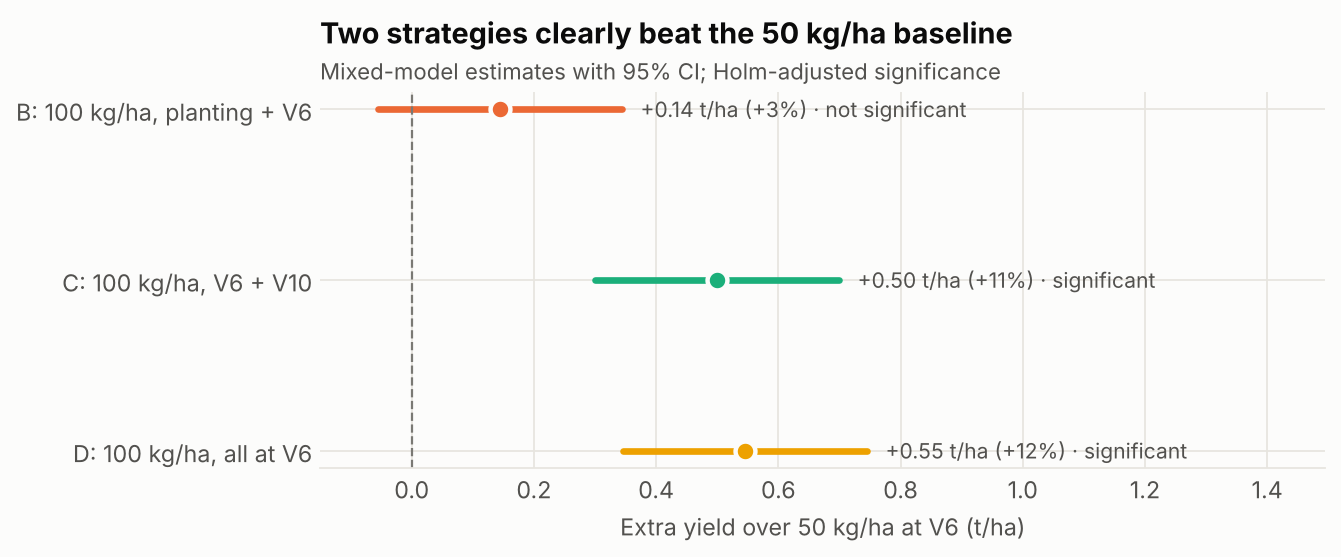

In [5]:
plotting.treatment_gains(te["gains"], OUT.figures / "treatment_gains_vs_baseline.png")
display(Image(OUT.figures / "treatment_gains_vs_baseline.png", width=760))

## 3. All pairwise comparisons

Six comparisons, Holm-adjusted to control the chance of any false positive.

In [6]:
te["pairwise"][["label", "difference_b_minus_a", "ci_low", "ci_high", "p_holm", "significant"]]

,label,difference_b_minus_a,ci_low,ci_high,p_holm,significant
0,B · 100 kg Plant+V6 vs A · 50 kg V6,0.144,-0.056,0.344,3.152e-01,False
1,C · 100 kg V6+V10 vs A · 50 kg V6,0.500,0.300,0.700,4.570e-06,True
2,D · 100 kg V6 vs A · 50 kg V6,0.546,0.346,0.745,5.031e-07,True
3,C · 100 kg V6+V10 vs B · 100 kg Plant+V6,0.356,0.156,0.556,1.479e-03,True
4,D · 100 kg V6 vs B · 100 kg Plant+V6,0.402,0.201,0.602,3.358e-04,True
5,D · 100 kg V6 vs C · 100 kg V6+V10,0.046,-0.154,0.245,6.532e-01,False


**Reading the results**
* **D (all at V6)** and **C (V6 + V10)** both beat the baseline by about 0.5 t/ha, and they are statistically indistinguishable from each other.
* **B (planting + V6)** is not significantly better than the baseline and is clearly worse than C and D. The extra Urea pays off only when it is applied at V6 or later. Nitrogen applied at planting, before the crop can take it up, is likely lost to leaching.

## 4. Does the effect change by mega-environment or season?

Likelihood-ratio tests compare the model with and without a treatment × environment (or × season) interaction. Both are fitted by maximum likelihood.

In [7]:
pd.DataFrame([analysis.interaction_test(df, "meg_env"), analysis.interaction_test(df, "season")])

,interaction,lr_statistic,df,p_value
0,Treatment x meg_env,9.142,9,0.424
1,Treatment x season,10.564,6,0.103


Neither interaction is significant at 5%. The data does not support different recommendations for different environments or seasons, and the pooled estimate is the most precise basis for advice.

## 5. Best treatment in each mega-environment

The brief asks for the best treatment per mega-environment, so a separate model is fitted within each one. These estimates are less precise than the pooled one. The implausible yield is excluded here because, in a single environment's model, it distorts the Low-Mid-Dry estimates.

In [8]:
per_env = analysis.per_environment(df[~df["flag_implausible_yield"]].copy())
best = per_env[per_env["is_best"]][["meg_env", "n_fields", "label", "gain_vs_baseline", "ci_low", "ci_high",
                                    "p_holm_vs_baseline", "best_vs_runner_up_diff", "best_vs_runner_up_p_holm"]]
best

,meg_env,n_fields,label,gain_vs_baseline,ci_low,ci_high,p_holm_vs_baseline,best_vs_runner_up_diff,best_vs_runner_up_p_holm
3,Highlands,142,"D: 100 kg/ha, all at V6",0.486,0.277,0.694,3.049e-05,0.127,0.468
7,Low-Mid-Dry,115,"D: 100 kg/ha, all at V6",0.499,0.326,0.672,9.607e-08,0.189,0.066
11,Low-Mid-Wet,77,"D: 100 kg/ha, all at V6",0.805,0.611,0.999,2.450e-15,0.024,0.812
15,Transitional,65,"D: 100 kg/ha, all at V6",0.453,0.165,0.740,1.024e-02,0.383,0.037


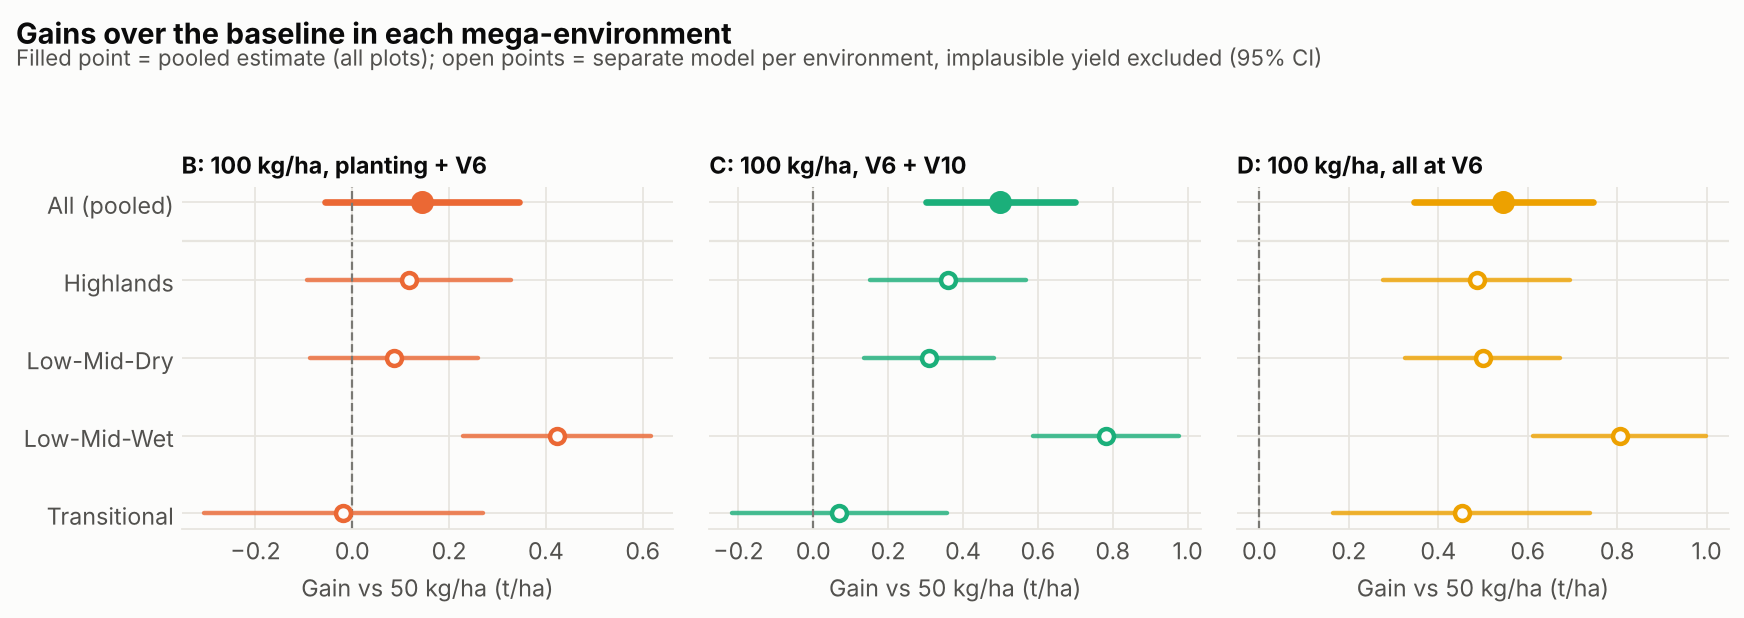

label,"A: 50 kg/ha, all at V6","B: 100 kg/ha, planting + V6","C: 100 kg/ha, V6 + V10","D: 100 kg/ha, all at V6"
meg_env,,,,
Highlands,0.0,0.12,0.36,0.49
Low-Mid-Dry,0.0,0.09,0.31,0.50
Low-Mid-Wet,0.0,0.42,0.78,0.81
Transitional,0.0,-0.02,0.07,0.45


In [9]:
plotting.per_environment_gains(per_env, te["gains"], OUT.figures / "per_environment_gains.png")
display(Image(OUT.figures / "per_environment_gains.png", width=950))
per_env.pivot(index="meg_env", columns="label", values="gain_vs_baseline").round(2)

**D ranks first in all four mega-environments**, and its gain over the baseline is significant in each.
* It is statistically tied with C in the Highlands, Low-Mid-Dry and Low-Mid-Wet.
* In the **Transitional** zone, D also beats C.
* **Low-Mid-Wet** fields respond most strongly to the extra Urea (~0.8 t/ha). Even B is worthwhile there.

## 6. Sensitivity to the implausible yield (50.1 t/ha)

In [10]:
analysis.outlier_sensitivity(df)[["label", "gain_all_plots", "p_holm_all_plots", "gain_without_implausible", "p_holm_without_implausible", "change"]]

,label,gain_all_plots,p_holm_all_plots,gain_without_implausible,p_holm_without_implausible,change
0,"B: 100 kg/ha, planting + V6",0.144,3.152e-01,0.145,8.593e-03,9.987e-04
1,"C: 100 kg/ha, V6 + V10",0.500,4.570e-06,0.380,2.343e-11,-1.202e-01
2,"D: 100 kg/ha, all at V6",0.546,5.031e-07,0.546,2.563e-22,-6.661e-16


D's estimate does not change. C's drops by about 0.12 t/ha, because the suspect plot is a C plot. B becomes significant without the outlier but stays small. The recommendation is robust.

## 7. Model diagnostics

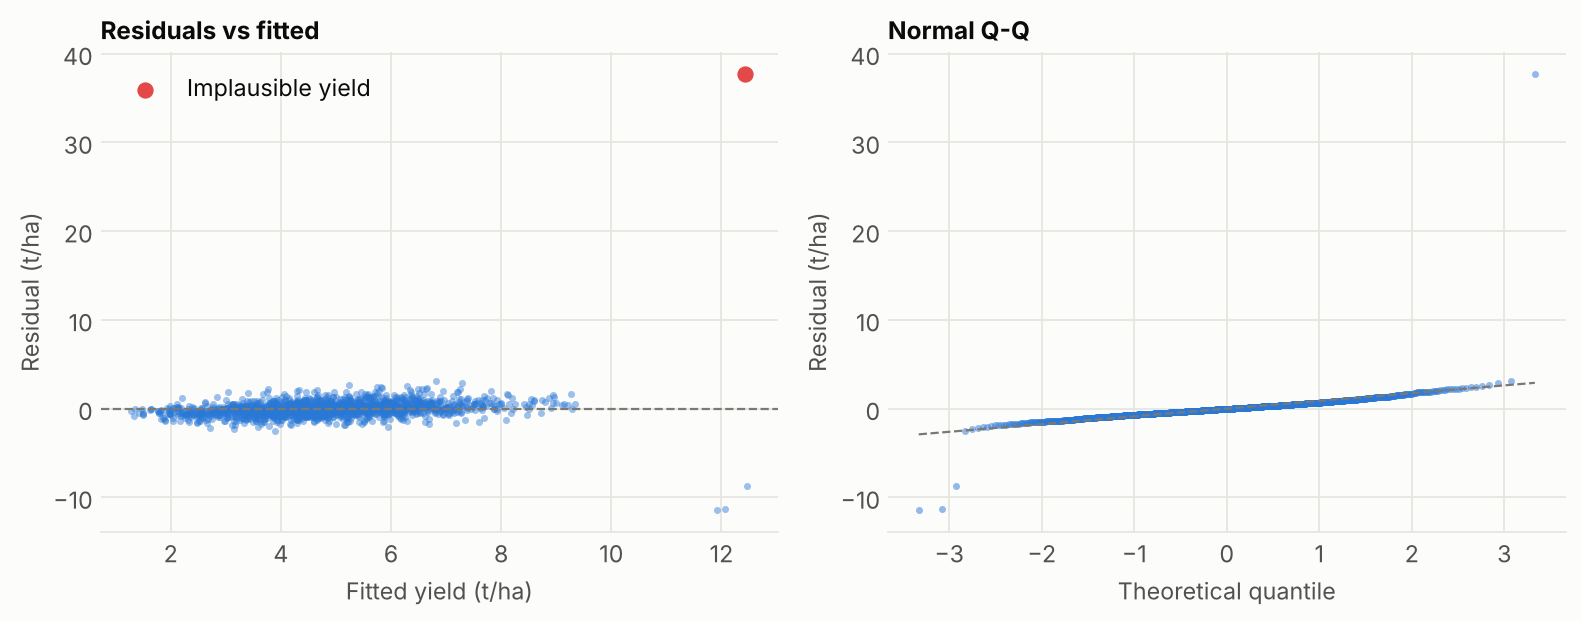

,component,variance,share
0,Between fields (random intercept),2.049,0.497
1,Within field (residual),2.070,0.503


In [11]:
res = analysis.residual_frame(df)
plotting.residual_diagnostics(res, OUT.figures / "residual_diagnostics.png")
display(Image(OUT.figures / "residual_diagnostics.png", width=820))
te["variance"]

Apart from the single implausible plot, the residuals are centred and roughly symmetric. About half of the yield variance lies between fields, which confirms that the random field effect is needed.

## 8. Other management factors

Adding compost, seed rate, DAP and germination rate to the mixed model:

In [12]:
analysis.agronomic_drivers(df)

,variable,effect_per_unit,se,ci_low,ci_high,p_value,n_obs
0,compost_tha,-0.040,0.027,-0.092,0.013,1.423e-01,1593
1,seeds_kgha,-0.005,0.017,-0.038,0.028,7.644e-01,1593
2,dap_kgha,-0.051,0.059,-0.168,0.065,3.897e-01,1593
3,germination_rate,0.029,0.006,0.018,0.040,3.900e-07,1593


Only **germination rate** has a clear effect: each extra percentage point of emergence adds about 0.03 t/ha. Compost, seed rate and DAP show no significant within-model effect (DAP barely varies, since all plots received 100 kg/ha). Adding them does not change the treatment estimates.

## Conclusion

| Question | Answer |
|---|---|
| Highest-yielding treatment | **D: 100 kg/ha all at V6** (+0.55 t/ha, p < 0.001); C equivalent (p = 0.65 vs D) |
| Best per mega-environment | D in all four; significantly better than C only in Transitional |
| Do effects differ by environment or season? | No (p = 0.42 and p = 0.10) |
| Robust to the implausible yield? | Yes for D; C's gain falls to +0.38 t/ha |

**Next:** notebook 05 adds rainfall and soil data.